In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

In [2]:
K = tf.keras
L = tf.keras.layers

In [3]:
#dataset
root = "caltech-101"
names = [c for c in sorted(os.listdir(root)) if c != "BACKGROUND_Google"]   # 101 object classes: drop the background folder
kw = dict(image_size=(96,96),batch_size=32,validation_split=0.2,seed=42,class_names=names)
tr = K.utils.image_dataset_from_directory(root,subset="training",**kw)
va = K.utils.image_dataset_from_directory(root,subset="validation",**kw)
#tr = tr.take(60)                  # optional: faster on a slow CPU

Found 8677 files belonging to 101 classes.
Using 6942 files for training.
Found 8677 files belonging to 101 classes.
Using 1735 files for validation.


In [4]:
#load base model
base = K.applications.VGG16(include_top=False,input_shape=(96,96,3),weights="vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5")
base.trainable = False
model = K.Sequential([L.Input((96,96,3)), L.Lambda(K.applications.vgg16.preprocess_input), base, L.GlobalAveragePooling2D(),L.Dense(256,activation="relu"), L.Dropout(0.3), L.Dense(len(va.class_names),activation="softmax")])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                      │ (None, 96, 96, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 3, 3, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 512)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 101)                 │          25,957 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,871,973 (56.73 MB)

 Trainable params: 157,285 (614.39 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [5]:
#compile
model.compile(optimizer=K.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = model.fit(tr, validation_data=va, epochs=4)

Epoch 1/4
217/217 ━━━━━━━━━━━━━━━━━━━━ 95s 433ms/step - accuracy: 0.3412 - loss: 7.7088 - val_accuracy: 0.6669 - val_loss: 1.5897
Epoch 2/4
217/217 ━━━━━━━━━━━━━━━━━━━━ 95s 436ms/step - accuracy: 0.7067 - loss: 1.3143 - val_accuracy: 0.7372 - val_loss: 1.1953
Epoch 3/4
217/217 ━━━━━━━━━━━━━━━━━━━━ 97s 447ms/step - accuracy: 0.8066 - loss: 0.7748 - val_accuracy: 0.7666 - val_loss: 1.0849
Epoch 4/4
217/217 ━━━━━━━━━━━━━━━━━━━━ 95s 439ms/step - accuracy: 0.8666 - loss: 0.4878 - val_accuracy: 0.7746 - val_loss: 1.0382


In [6]:
#evaluate
model.evaluate(va)
X, y = zip(*va.as_numpy_iterator())
X, y = np.concatenate(X), np.concatenate(y) 
prob = model.predict(X)
pred = prob.argmax(1)
print("top-5 accuracy:", np.mean([t in r for t, r in zip(y, np.argsort(-prob, 1)[:, :5])]))     # right class among the 5 best guesses
print(classification_report(y, pred, target_names=va.class_names))

55/55 ━━━━━━━━━━━━━━━━━━━━ 21s 373ms/step - accuracy: 0.7738 - loss: 1.0755
55/55 ━━━━━━━━━━━━━━━━━━━━ 21s 369ms/step
top-5 accuracy: 0.9043227665706052
                 precision    recall  f1-score   support

          Faces       1.00      0.96      0.98        80
     Faces_easy       1.00      0.98      0.99        84
       Leopards       0.84      0.95      0.89        44
     Motorbikes       0.97      1.00      0.98       148
      accordion       1.00      0.91      0.95        11
      airplanes       0.94      0.96      0.95       160
         anchor       0.80      0.27      0.40        15
            ant       1.00      0.09      0.17        11
         barrel       1.00      0.67      0.80         9
           bass       0.67      0.18      0.29        11
         beaver       0.58      0.54      0.56        13
      binocular       0.67      0.44      0.53         9
         bonsai       0.72      0.88      0.79        24
          brain       0.64      0.90      0.75  

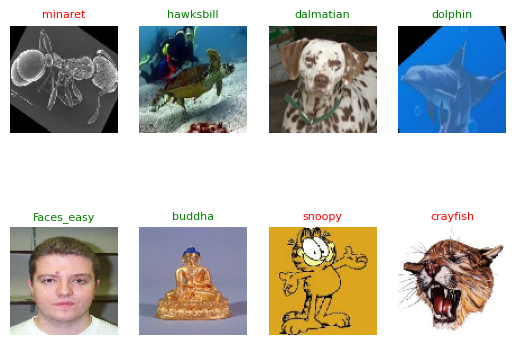

In [7]:
#plot
for i in range(8):
    plt.subplot(2, 4, i + 1); plt.imshow(X[i].astype("uint8")); plt.axis("off")
    plt.title(va.class_names[pred[i]], color="g" if pred[i] == y[i] else "r", fontsize=8)
plt.show()

In [8]:
#fine tune
base.trainable = True
for l in base.layers[:-4]:
    l.trainable = False
model.compile(optimizer=K.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(tr, validation_data=va, epochs=2)
print(model.evaluate(va))

Epoch 1/2
217/217 ━━━━━━━━━━━━━━━━━━━━ 124s 561ms/step - accuracy: 0.9055 - loss: 0.3401 - val_accuracy: 0.7914 - val_loss: 0.9761
Epoch 2/2
217/217 ━━━━━━━━━━━━━━━━━━━━ 94s 432ms/step - accuracy: 0.9350 - loss: 0.2322 - val_accuracy: 0.7988 - val_loss: 0.9662
55/55 ━━━━━━━━━━━━━━━━━━━━ 13s 226ms/step - accuracy: 0.8061 - loss: 0.9688
[0.9661834239959717, 0.7988472580909729]


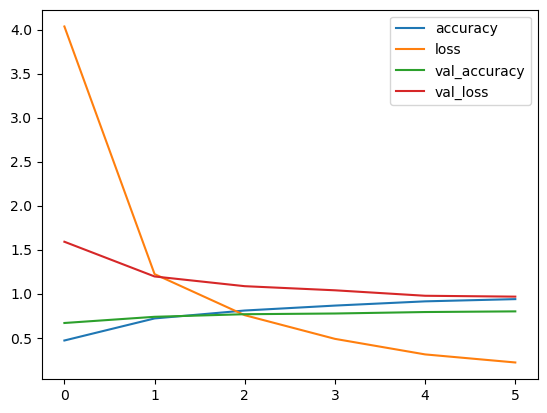

In [9]:
#compare
pd.concat([pd.DataFrame(h1.history), pd.DataFrame(h2.history)], ignore_index=True).plot()
plt.show()